C:\Users\user\AppData\Local\Temp\ipykernel_33100\3163543202.py:7: FutureWarning: 'M' is deprecated and will be removed in a future version, please use 'ME' instead.
  'ds': pd.date_range('2020-01-01', periods=60, freq='M'),
22:49:59 - cmdstanpy - INFO - Chain [1] start processing
22:50:00 - cmdstanpy - INFO - Chain [1] done processing
C:\Users\user\AppData\Roaming\Python\Python311\site-packages\prophet\forecaster.py:1872: FutureWarning: 'M' is deprecated and will be removed in a future version, please use 'ME' instead.
  dates = pd.date_range(


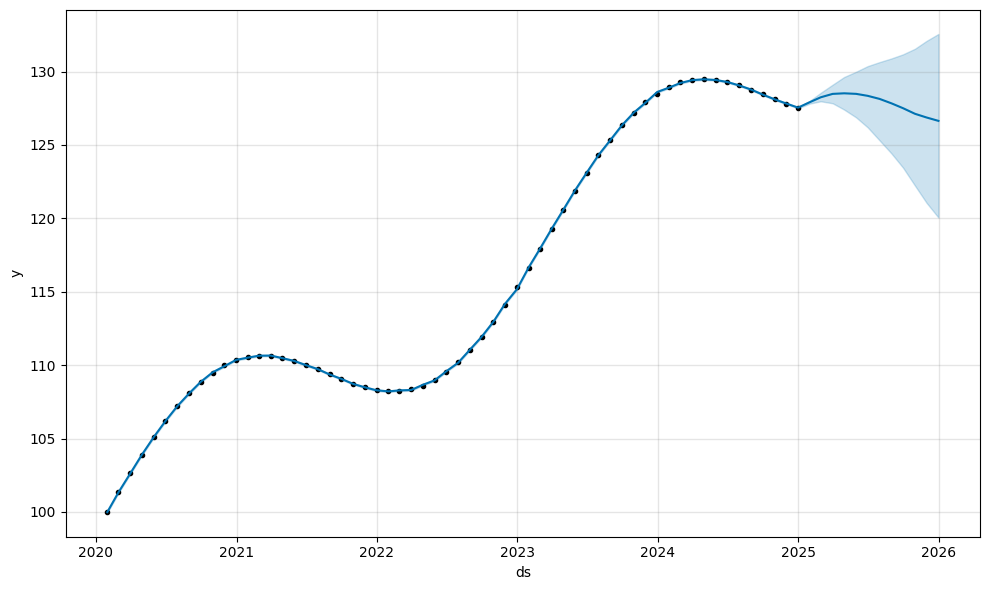

In [ ]:
import numpy as np
from prophet import Prophet
import pandas as pd

df = pd.DataFrame({
    'ds': pd.date_range('2020-01-01', periods=60, freq='M'),
    'y': [100 + i*0.5 + 5*np.sin(i/6) for i in range(60)]  # trend + seasonality
})

model = Prophet(yearly_seasonality=True)
model.fit(df)

future = model.make_future_dataframe(periods=12, freq='M')
forecast = model.predict(future)

model.plot(forecast);


In [ ]:
import pandas as pd
import statsmodels.api as sm
import numpy as np

df = pd.DataFrame({
    'price': [350000, 420000, 300000, 500000, 450000],
    'sqft': [1200, 1400, 1000, 1600, 1500],
    'bedrooms': [3, 4, 2, 4, 3],
    'dist_to_cbd_km': [5, 3, 8, 2, 4],
})

df['log_price'] = np.log(df['price'])

# Define predictors
X = sm.add_constant(df[['sqft', 'bedrooms', 'dist_to_cbd_km']])
y = df['log_price']

# Fit a GLM with Gaussian family and log link
model = sm.GLM(y, X, family=sm.families.Gaussian(sm.families.links.identity()))
result = model.fit()

print(result.summary())


                 Generalized Linear Model Regression Results                  
Dep. Variable:              log_price   No. Observations:                    5
Model:                            GLM   Df Residuals:                        1
Model Family:                Gaussian   Df Model:                            3
Link Function:               identity   Scale:                      0.00013123
Method:                          IRLS   Log-Likelihood:                 19.275
Date:                Sun, 19 Oct 2025   Deviance:                   0.00013123
Time:                        05:52:57   Pearson chi2:                 0.000131
No. Iterations:                     3   Pseudo R-squ. (CS):              1.000
Covariance Type:            nonrobust                                         
                     coef    std err          z      P>|z|      [0.025      0.975]
----------------------------------------------------------------------------------
const             11.2878      0.432     26.

C:\Users\user\AppData\Roaming\Python\Python311\site-packages\statsmodels\genmod\families\links.py:13: FutureWarning: The identity link alias is deprecated. Use Identity instead. The identity link alias will be removed after the 0.15.0 release.
  warnings.warn(


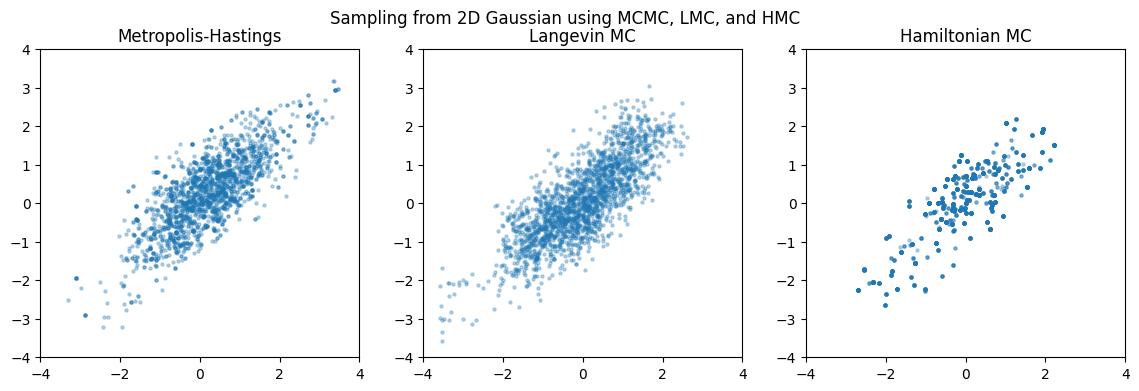

In [ ]:
import numpy as np
import matplotlib.pyplot as plt

# --- Target distribution: 2D Gaussian ---
mean = np.array([0., 0.])
cov = np.array([[1.0, 0.8],
                [0.8, 1.0]])
inv_cov = np.linalg.inv(cov)

def log_prob(x):
    """Log probability of 2D Gaussian (up to constant)."""
    return -0.5 * x @ inv_cov @ x

# --- 1️. Metropolis-Hastings (basic MCMC) ---
def metropolis_hastings(n_samples=2000, step_size=0.5):
    samples = []
    x = np.zeros(2)
    for _ in range(n_samples):
        proposal = x + step_size * np.random.randn(2)
        accept_ratio = np.exp(log_prob(proposal) - log_prob(x))
        if np.random.rand() < accept_ratio:
            x = proposal
        samples.append(x)
    return np.array(samples)

# --- 2️. Langevin Monte Carlo (LMC) ---
def langevin_monte_carlo(n_samples=2000, step_size=0.1):
    samples = []
    x = np.zeros(2)
    for _ in range(n_samples):
        grad = -inv_cov @ x  # gradient of log_prob(x)
        proposal = x + 0.5 * step_size * grad + np.sqrt(step_size) * np.random.randn(2)
        x = proposal
        samples.append(x)
    return np.array(samples)

# --- 3️. Hamiltonian Monte Carlo (HMC) ---
def hmc(n_samples=2000, step_size=0.1, L=10):
    samples = []
    x = np.zeros(2)
    for _ in range(n_samples):
        p = np.random.randn(2)  # momentum
        x_new, p_new = x.copy(), p.copy()
        # Leapfrog integration
        p_new -= 0.5 * step_size * (-inv_cov @ x_new)
        for _ in range(L):
            x_new += step_size * p_new
            if _ != L - 1:
                p_new -= step_size * (-inv_cov @ x_new)
        p_new -= 0.5 * step_size * (-inv_cov @ x_new)
        # Metropolis acceptance
        old_H = -log_prob(x) + 0.5 * np.dot(p, p)
        new_H = -log_prob(x_new) + 0.5 * np.dot(p_new, p_new)
        if np.random.rand() < np.exp(old_H - new_H):
            x = x_new
        samples.append(x)
    return np.array(samples)


mh_samples = metropolis_hastings()
lmc_samples = langevin_monte_carlo()
hmc_samples = hmc()

fig, axes = plt.subplots(1, 3, figsize=(14, 4))
titles = ["Metropolis-Hastings", "Langevin MC", "Hamiltonian MC"]
for ax, s, title in zip(axes, [mh_samples, lmc_samples, hmc_samples], titles):
    ax.scatter(s[:, 0], s[:, 1], s=5, alpha=0.3)
    ax.set_title(title)
    ax.set_xlim(-4, 4)
    ax.set_ylim(-4, 4)
plt.suptitle("Sampling from 2D Gaussian using MCMC, LMC, and HMC")
plt.show()


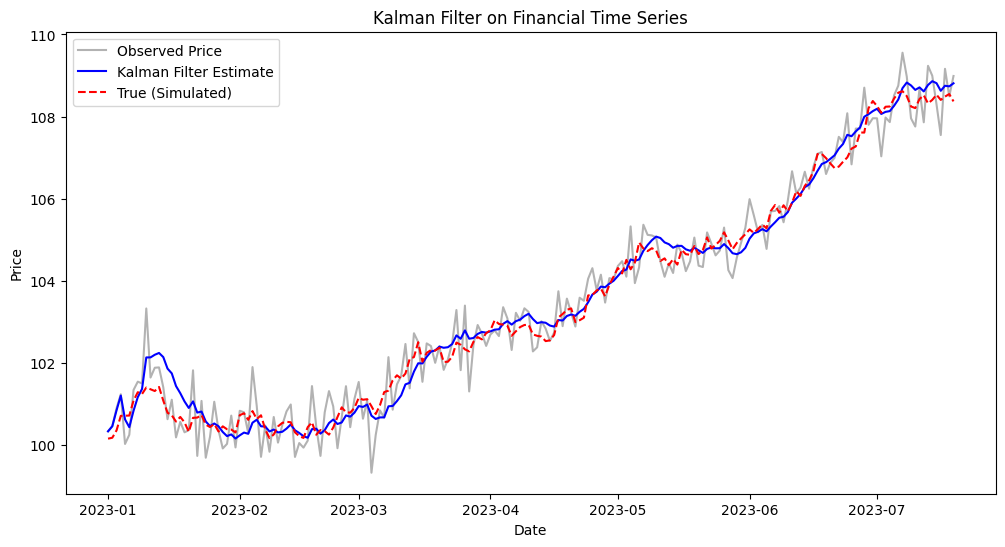

In [ ]:
#  a Kalman Filter to smooth a stock price time series

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from filterpy.kalman import KalmanFilter

# simulate a noisy price series
np.random.seed(42)
n = 200
true_price = np.cumsum(np.random.randn(n) * 0.2 + 0.05) + 100  # underlying trend
observed_price = true_price + np.random.randn(n) * 0.5  # noisy observations

dates = pd.date_range("2023-01-01", periods=n)
df = pd.DataFrame({"Observed": observed_price, "True": true_price}, index=dates)

# Kalman Filter

kf = KalmanFilter(dim_x=2, dim_z=1)

# State: [price, velocity]
kf.x = np.array([[df["Observed"].iloc[0]], [0]])  # initial state estimate

# State transition matrix
kf.F = np.array([[1, 1],
                 [0, 1]])

# Observation matrix
kf.H = np.array([[1, 0]])

# Covariances
kf.P *= 1000.0      # initial uncertainty
kf.R = 0.5**2       # measurement noise
kf.Q = np.array([[1e-4, 0],
                 [0, 1e-4]])  # process noise


filtered_state_means = []
for z in df["Observed"].values:
    kf.predict()
    kf.update(z)
    filtered_state_means.append(kf.x[0, 0])

df["Kalman_Filtered"] = filtered_state_means

plt.figure(figsize=(12, 6))
plt.plot(df.index, df["Observed"], color="gray", alpha=0.6, label="Observed Price")
plt.plot(df.index, df["Kalman_Filtered"], color="blue", label="Kalman Filter Estimate")
plt.plot(df.index, df["True"], color="red", linestyle="--", label="True (Simulated)")
plt.title("Kalman Filter on Financial Time Series")
plt.xlabel("Date")
plt.ylabel("Price")
plt.legend()
plt.show()


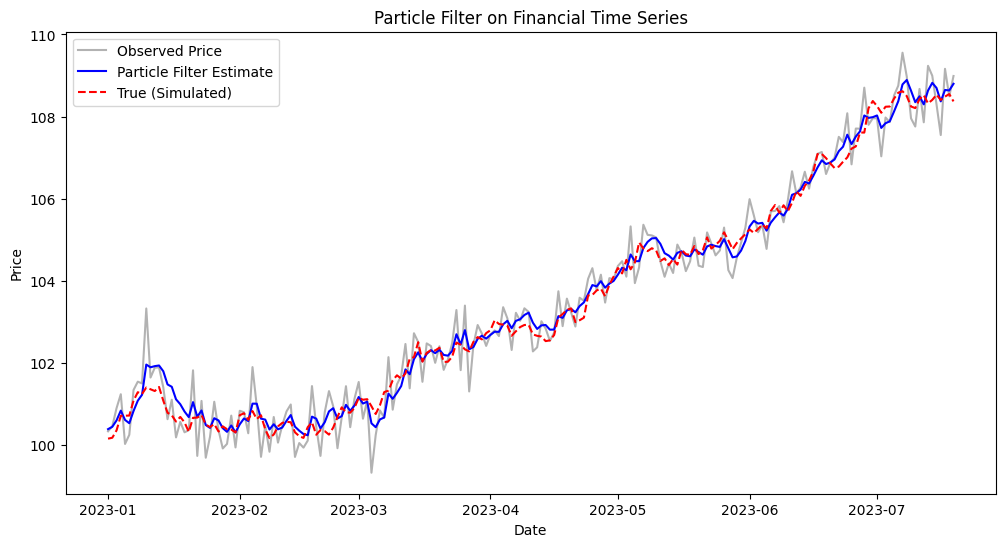

In [ ]:
# a particle filter to estimate the true price of a noisy financial time series

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# 1. Simulate data

np.random.seed(42)
n = 200
true_price = np.cumsum(np.random.randn(n) * 0.2 + 0.05) + 100  # underlying trend
observed_price = true_price + np.random.randn(n) * 0.5         # noisy measurements

dates = pd.date_range("2023-01-01", periods=n)
df = pd.DataFrame({"Observed": observed_price, "True": true_price}, index=dates)

# Define Particle Filter

class ParticleFilter:
    def __init__(self, n_particles, process_noise, measurement_noise):
        self.n_particles = n_particles
        self.process_noise = process_noise
        self.measurement_noise = measurement_noise
        self.particles = None
        self.weights = None

    def initialize(self, initial_value):
        self.particles = np.ones(self.n_particles) * initial_value
        self.weights = np.ones(self.n_particles) / self.n_particles

    def predict(self):
        # Propagate particles according to motion model (random walk with drift)
        drift = 0.05  # average upward drift
        self.particles += drift + np.random.randn(self.n_particles) * self.process_noise

    def update(self, measurement):
        # Compute importance weights based on observation likelihood
        likelihood = np.exp(-0.5 * ((measurement - self.particles) ** 2) / self.measurement_noise**2)
        self.weights *= likelihood
        self.weights += 1e-300  # avoid zero weights
        self.weights /= np.sum(self.weights)

    def resample(self):
        # Resample particles proportional to their weights (systematic resampling)
        indices = np.random.choice(self.n_particles, size=self.n_particles, p=self.weights)
        self.particles = self.particles[indices]
        self.weights.fill(1.0 / self.n_particles)

    def estimate(self):
        # Weighted mean as state estimate
        return np.average(self.particles, weights=self.weights)

n_particles = 500
pf = ParticleFilter(n_particles, process_noise=0.2, measurement_noise=0.5)
pf.initialize(df["Observed"].iloc[0])

estimates = []

for z in df["Observed"].values:
    pf.predict()
    pf.update(z)
    pf.resample()
    estimates.append(pf.estimate())

df["Particle_Filtered"] = estimates

plt.figure(figsize=(12, 6))
plt.plot(df.index, df["Observed"], color="gray", alpha=0.6, label="Observed Price")
plt.plot(df.index, df["Particle_Filtered"], color="blue", label="Particle Filter Estimate")
plt.plot(df.index, df["True"], color="red", linestyle="--", label="True (Simulated)")
plt.title("Particle Filter on Financial Time Series")
plt.xlabel("Date")
plt.ylabel("Price")
plt.legend()
plt.show()
